❌ tensorflow NOT installed
✅ torch installed (version 2.15.0+cpu)

✅ Total MRI Scans Indexed: 6,400

Class & Split Breakdown:
split             train   All
class                        
MildDemented        896   896
ModerateDemented     64    64
NonDemented        3200  3200
VeryMildDemented   2240  2240
All                6400  6400


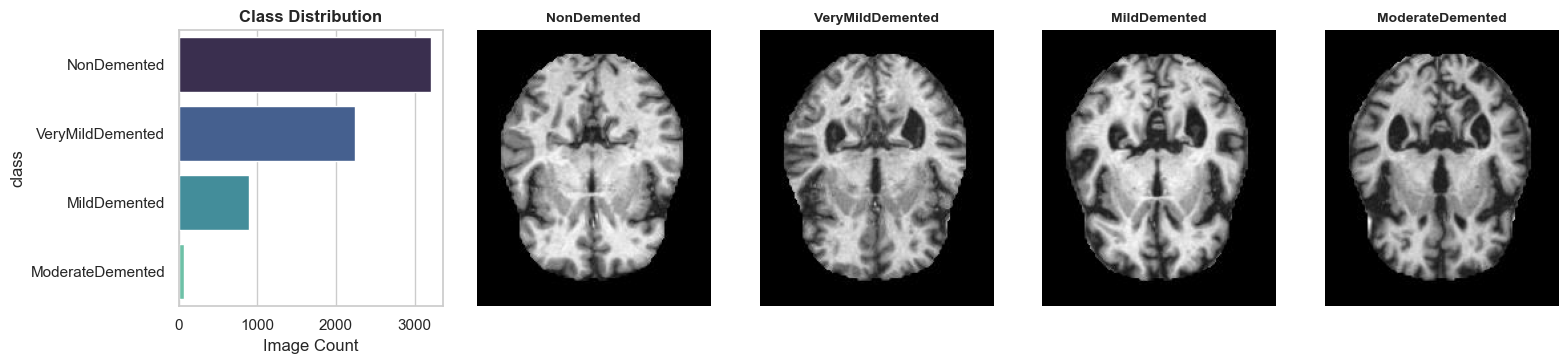

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# 1. Check installed Deep Learning frameworks
for pkg in ["tensorflow", "torch"]:
    try:
        mod = __import__(pkg)
        print(f"✅ {pkg} installed (version {mod.__version__})")
    except ImportError:
        print(f"❌ {pkg} NOT installed")

# 2. Index the 4-class Brain MRI dataset inside data/
target_classes = ["NonDemented", "VeryMildDemented", "MildDemented", "ModerateDemented"]
records = []

for root, dirs, files in os.walk("data"):
    folder_name = os.path.basename(root)
    if folder_name in target_classes:
        split_name = "test" if "test" in root.lower() else "train"
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                records.append({
                    "filepath": os.path.join(root, f),
                    "class": folder_name,
                    "split": split_name,
                })

if not records:
    raise FileNotFoundError(
        "No MRI images found in data/! Check that NonDemented, VeryMildDemented, MildDemented, and ModerateDemented folders are inside data/."
    )

df = pd.DataFrame(records)
print(f"\n✅ Total MRI Scans Indexed: {len(df):,}")
print("\nClass & Split Breakdown:")
print(pd.crosstab(df["class"], df["split"], margins=True))

# 3. Save EDA Overview Chart (Class Imbalance + 1 Sample Scan per Stage)
os.makedirs("visuals", exist_ok=True)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.8))

counts = df["class"].value_counts().reindex(target_classes)
sns.barplot(x=counts.values, y=counts.index, ax=axes[0], palette="mako")
axes[0].set_title("Class Distribution", fontweight="bold")
axes[0].set_xlabel("Image Count")

for idx, cls in enumerate(target_classes, start=1):
    sample_path = df[df["class"] == cls]["filepath"].iloc[0]
    img = Image.open(sample_path).convert("RGB")
    axes[idx].imshow(img)
    axes[idx].set_title(cls, fontsize=10, fontweight="bold")
    axes[idx].axis("off")

plt.tight_layout()
plt.savefig("visuals/mri_eda_overview.png", dpi=300)
plt.show()

In [5]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# Reproducibility & Device
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# Map 4 dementia stages to integer labels
label_to_idx = {cls: i for i, cls in enumerate(target_classes)}
idx_to_label = {i: cls for cls, i in label_to_idx.items()}
df["label"] = df["class"].map(label_to_idx)

# Stratified 80/20 Train/Test Split (preserves rare ModerateDemented class!)
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df["label"]
)
print(f"Train Scans: {len(train_df):,} | Unseen Test Scans: {len(test_df):,}")

# Compute Inverse-Frequency Class Weights for Imbalanced Loss
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(target_classes)),
    y=train_df["label"].values,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("Class Weights (to handle 50:1 imbalance):", dict(zip(target_classes, np.round(class_weights, 2))))

# Image Preprocessing & Medical-Safe Data Augmentation (gentle rotation & brightness, no vertical flips!)
IMG_SIZE = 160
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class BrainMRIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.paths = dataframe["filepath"].values
        self.labels = dataframe["label"].values
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)

train_loader = DataLoader(BrainMRIDataset(train_df, train_transform), batch_size=32, shuffle=True)
test_loader = DataLoader(BrainMRIDataset(test_df, val_transform), batch_size=32, shuffle=False)

# Build Pretrained ResNet18 Classifier (Fine-tuning Layer3, Layer4 & Classification Head)
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for param in model.parameters():
    param.requires_grad = False
for param in model.layer3.parameters():
    param.requires_grad = True
for param in model.layer4.parameters():
    param.requires_grad = True

model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(model.fc.in_features, 4)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=3e-4, weight_decay=1e-4)

# Train for 6 Epochs (~2-3 minutes on CPU, ~20 seconds on GPU)
EPOCHS = 6
history = {"train_loss": [], "train_acc": [], "val_acc": []}
best_acc = 0.0
best_weights = copy.deepcopy(model.state_dict())

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Evaluate on Unseen Test Scans
    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_acc > best_acc:
        best_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch}/{EPOCHS} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Unseen Test Acc: {val_acc*100:.2f}%")

model.load_state_dict(best_weights)
print(f"\n🏆 Best Unseen Test Accuracy: {best_acc*100:.2f}%")

Training on device: cpu
Train Scans: 5,120 | Unseen Test Scans: 1,280
Class Weights (to handle 50:1 imbalance): {'NonDemented': 0.5, 'VeryMildDemented': 0.71, 'MildDemented': 1.79, 'ModerateDemented': 25.1}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|█████████████████████████████████████████████████████████████████████████████| 44.7M/44.7M [00:04<00:00, 9.72MB/s]


Epoch 1/6 | Train Loss: 1.0181 | Train Acc: 52.83% | Unseen Test Acc: 64.61%
Epoch 2/6 | Train Loss: 0.6346 | Train Acc: 67.62% | Unseen Test Acc: 66.80%
Epoch 3/6 | Train Loss: 0.4820 | Train Acc: 76.41% | Unseen Test Acc: 80.47%
Epoch 4/6 | Train Loss: 0.3414 | Train Acc: 82.75% | Unseen Test Acc: 78.20%
Epoch 5/6 | Train Loss: 0.2896 | Train Acc: 86.48% | Unseen Test Acc: 87.27%
Epoch 6/6 | Train Loss: 0.2349 | Train Acc: 88.93% | Unseen Test Acc: 89.77%

🏆 Best Unseen Test Accuracy: 89.77%


📊 Unseen Test Set Macro ROC-AUC:    0.9905
📊 Unseen Test Set Weighted ROC-AUC: 0.9847

=== CLASSIFICATION REPORT (1,280 UNSEEN MRI SCANS) ===
                  precision    recall  f1-score   support

     NonDemented     0.9799    0.8359    0.9022       640
VeryMildDemented     0.8275    0.9531    0.8859       448
    MildDemented     0.8488    0.9721    0.9062       179
ModerateDemented     1.0000    1.0000    1.0000        13

        accuracy                         0.8977      1280
       macro avg     0.9140    0.9403    0.9236      1280
    weighted avg     0.9084    0.8977    0.8980      1280



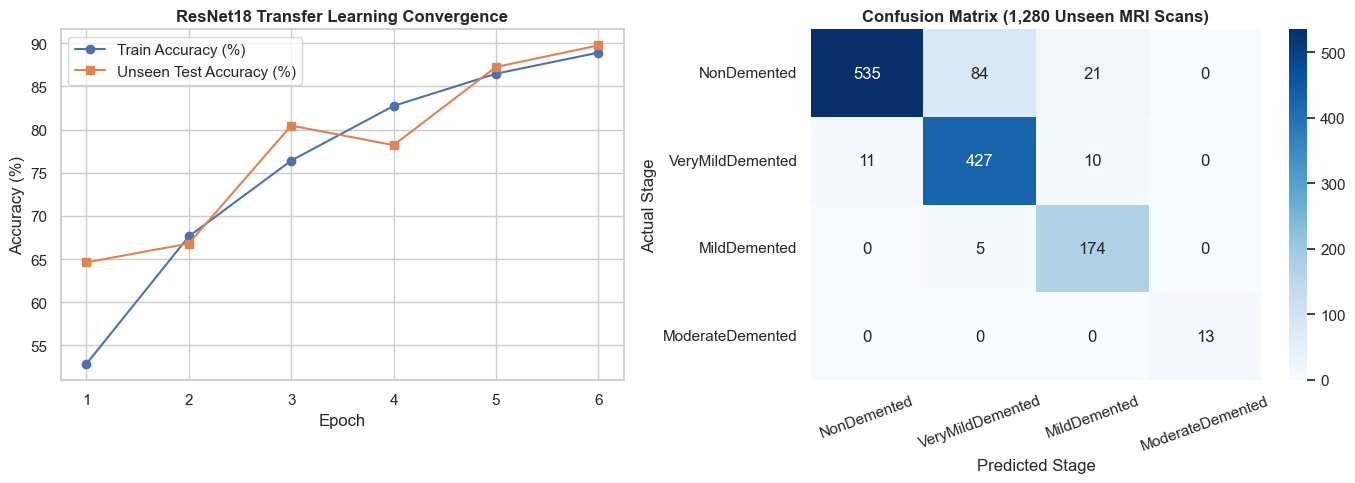

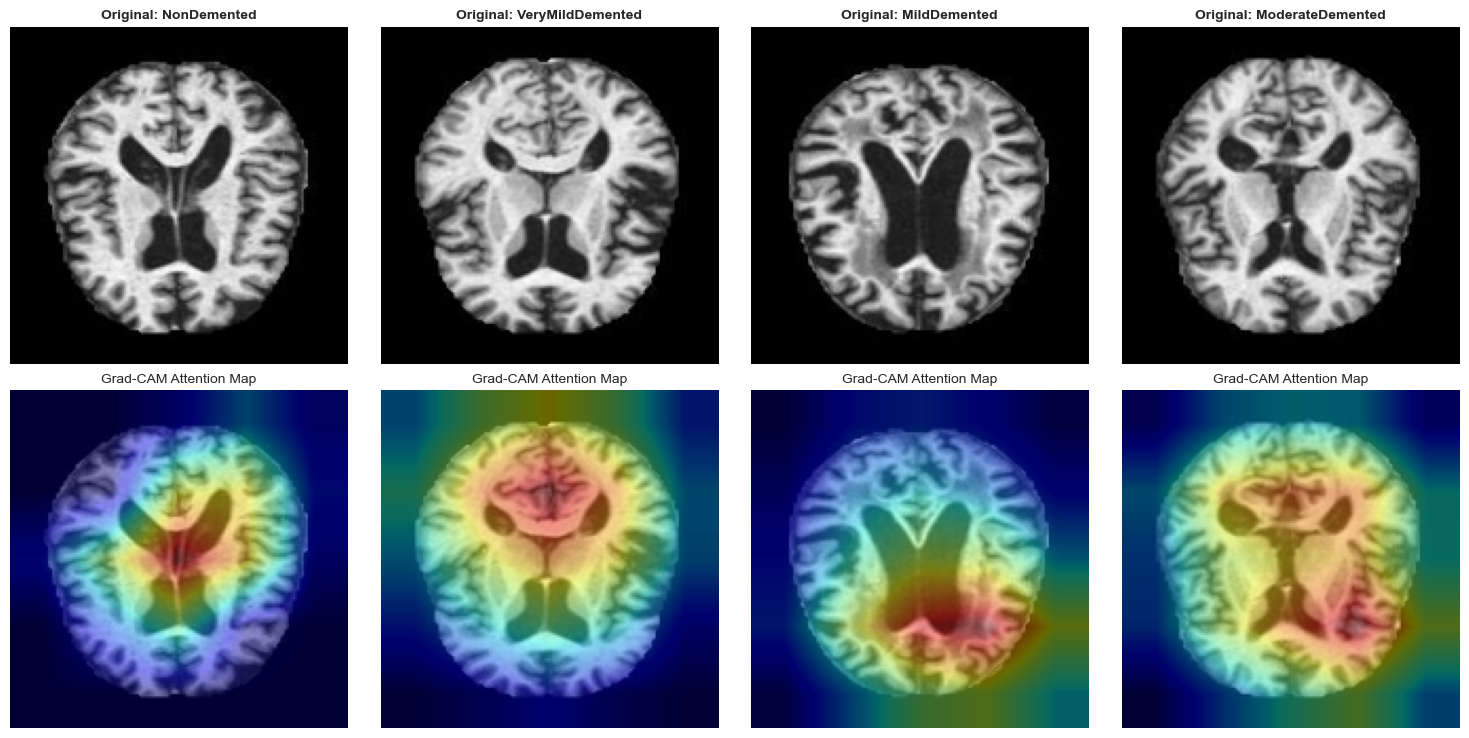

✅ Saved trained PyTorch model + metrics to: models/alzheimers_resnet18.pth
✅ Saved 4 unseen demo MRI scans to: sample_mris/


In [7]:
import shutil
import torch.nn.functional as F
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

os.makedirs("models", exist_ok=True)
os.makedirs("visuals", exist_ok=True)
os.makedirs("sample_mris", exist_ok=True)

# 1. Full Inference on All 1,280 Unseen Test Scans
model.eval()
all_preds, all_probs, all_labels = [], [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        logits = model(imgs)
        probs = F.softmax(logits, dim=1).cpu().numpy()
        preds = np.argmax(probs, axis=1)
        all_probs.append(probs)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_probs = np.vstack(all_probs)
all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Compute Multi-Class Macro & Weighted ROC-AUC
y_bin = label_binarize(all_labels, classes=[0, 1, 2, 3])
macro_auc = roc_auc_score(y_bin, all_probs, average="macro", multi_class="ovr")
weighted_auc = roc_auc_score(y_bin, all_probs, average="weighted", multi_class="ovr")

print(f"📊 Unseen Test Set Macro ROC-AUC:    {macro_auc:.4f}")
print(f"📊 Unseen Test Set Weighted ROC-AUC: {weighted_auc:.4f}\n")
print("=== CLASSIFICATION REPORT (1,280 UNSEEN MRI SCANS) ===")
print(classification_report(all_labels, all_preds, target_names=target_classes, digits=4))

# 2. Chart 1: Training Curve + Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history["train_acc"]) + 1)
axes[0].plot(epochs_range, [a * 100 for a in history["train_acc"]], marker="o", label="Train Accuracy (%)")
axes[0].plot(epochs_range, [a * 100 for a in history["val_acc"]], marker="s", label="Unseen Test Accuracy (%)")
axes[0].set_title("ResNet18 Transfer Learning Convergence", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()

cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=target_classes,
    yticklabels=target_classes,
    ax=axes[1],
)
axes[1].set_title("Confusion Matrix (1,280 Unseen MRI Scans)", fontweight="bold")
axes[1].set_xlabel("Predicted Stage")
axes[1].set_ylabel("Actual Stage")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("visuals/training_and_confusion_matrix.png", dpi=300)
plt.show()

# 3. Grad-CAM Explainability Generator
def compute_gradcam(model, img_tensor, target_class_idx):
    model.eval()
    activations, gradients = [], []

    def forward_hook(module, inp, out):
        activations.append(out.detach())

    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0].detach())

    target_layer = model.layer4[-1].conv2
    h1 = target_layer.register_forward_hook(forward_hook)
    h2 = target_layer.register_full_backward_hook(backward_hook)

    img_input = img_tensor.unsqueeze(0).to(device)
    output = model(img_input)
    model.zero_grad()
    output[0, target_class_idx].backward()

    h1.remove()
    h2.remove()

    grads = gradients[0][0]          # [C, H, W]
    acts = activations[0][0]         # [C, H, W]
    weights = grads.mean(dim=(1, 2)) # [C]
    cam = torch.zeros(acts.shape[1:], dtype=torch.float32, device=device)
    for w, a in zip(weights, acts):
        cam += w * a

    cam = F.relu(cam).cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam

# 4. Chart 2: Grad-CAM Attention Maps Across All 4 Dementia Stages + Copy 4 Sample Scans for Web App
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
cmap_jet = plt.get_cmap("jet")

for col_idx, cls in enumerate(target_classes):
    sample_row = test_df[test_df["class"] == cls].iloc[0]
    sample_path = sample_row["filepath"]
    shutil.copy(sample_path, f"sample_mris/{cls}.jpg")

    orig_pil = Image.open(sample_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    img_tensor = val_transform(orig_pil)
    cam = compute_gradcam(model, img_tensor, col_idx)

    # Resize Grad-CAM heatmap to IMG_SIZE and blend over original MRI
    cam_resized = np.array(Image.fromarray(np.uint8(cam * 255)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
    heatmap_rgb = np.uint8(cmap_jet(cam_resized)[:, :, :3] * 255)
    overlay = np.uint8(0.58 * np.array(orig_pil) + 0.42 * heatmap_rgb)

    axes[0, col_idx].imshow(orig_pil)
    axes[0, col_idx].set_title(f"Original: {cls}", fontsize=10, fontweight="bold")
    axes[0, col_idx].axis("off")

    axes[1, col_idx].imshow(overlay)
    axes[1, col_idx].set_title("Grad-CAM Attention Map", fontsize=10)
    axes[1, col_idx].axis("off")

plt.tight_layout()
plt.savefig("visuals/gradcam_explainability.png", dpi=300)
plt.show()

# 5. Export Model Checkpoint + Metadata Bundle
checkpoint = {
    "model_state_dict": model.cpu().state_dict(),
    "classes": target_classes,
    "img_size": IMG_SIZE,
    "test_accuracy": float(best_acc),
    "macro_auc": float(macro_auc),
    "weighted_auc": float(weighted_auc),
}
torch.save(checkpoint, "models/alzheimers_resnet18.pth")
print("✅ Saved trained PyTorch model + metrics to: models/alzheimers_resnet18.pth")
print("✅ Saved 4 unseen demo MRI scans to: sample_mris/")

In [9]:
app_code = '''import io
import os
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import plotly.graph_objects as go
import streamlit as st
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms

st.set_page_config(
    page_title="AI Alzheimer's MRI Detection & Clinical Screening",
    page_icon="🧠",
    layout="wide",
)

STAGE_DESCRIPTIONS = {
    "NonDemented": (
        "No radiographic signs of cortical atrophy or ventricular enlargement associated with Alzheimer's disease. "
        "Continue routine cognitive wellness habits, regular physical activity, and periodic health checkups."
    ),
    "VeryMildDemented": (
        "Subtle early hippocampal and medial temporal changes consistent with Very Mild Cognitive Impairment (prodromal stage). "
        "Early neurological evaluation, structured cognitive exercises, and lifestyle interventions are strongly advised."
    ),
    "MildDemented": (
        "Noticeable cortical thinning and memory-network changes consistent with Mild Alzheimer's Disease. "
        "Individuals typically experience challenges with recent recall and complex planning; timely clinical care and family support help slow progression."
    ),
    "ModerateDemented": (
        "Pronounced ventricular enlargement and diffuse cortical atrophy consistent with Moderate Alzheimer's Disease. "
        "Comprehensive neurological management, structured daily routines, and dedicated caregiver support are essential."
    ),
}

@st.cache_resource
def load_mri_model():
    ckpt = torch.load("models/alzheimers_resnet18.pth", map_location="cpu", weights_only=False)
    classes = ckpt["classes"]
    img_size = ckpt["img_size"]

    model = models.resnet18(weights=None)
    model.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(model.fc.in_features, len(classes)),
    )
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    return model, ckpt

model, ckpt = load_mri_model()
CLASSES = ckpt["classes"]
IMG_SIZE = ckpt["img_size"]

preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

def predict_with_gradcam(pil_img):
    orig_resized = pil_img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    input_tensor = preprocess(orig_resized).unsqueeze(0)

    activations, gradients = [], []

    def fwd_hook(module, inp, out):
        activations.append(out.detach())

    def bwd_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0].detach())

    target_layer = model.layer4[-1].conv2
    h1 = target_layer.register_forward_hook(fwd_hook)
    h2 = target_layer.register_full_backward_hook(bwd_hook)

    logits = model(input_tensor)
    probs = F.softmax(logits, dim=1)[0].detach().numpy()
    pred_idx = int(np.argmax(probs))

    model.zero_grad()
    logits[0, pred_idx].backward()
    h1.remove()
    h2.remove()

    grads = gradients[0][0]
    acts = activations[0][0]
    weights = grads.mean(dim=(1, 2))
    cam = torch.zeros(acts.shape[1:], dtype=torch.float32)
    for w, a in zip(weights, acts):
        cam += w * a

    cam = F.relu(cam).numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    cam_resized = np.array(Image.fromarray(np.uint8(cam * 255)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) / 255.0
    heatmap_rgb = np.uint8(plt.get_cmap("jet")(cam_resized)[:, :, :3] * 255)
    overlay = Image.fromarray(np.uint8(0.58 * np.array(orig_resized) + 0.42 * heatmap_rgb))
    return pred_idx, probs, orig_resized, overlay

st.title("🧠 AI-Enhanced Alzheimer's Disease Detection & Clinical Screening")
st.markdown(
    f"**Transfer Learning (`ResNet18`) + Grad-CAM Explainable AI + MMSE Cognitive Screening**  |  "
    f"Held-Out Test Accuracy: **{ckpt['test_accuracy']*100:.2f}%**  |  Macro ROC-AUC: **{ckpt['macro_auc']:.4f}**"
)

tab1, tab2, tab3 = st.tabs([
    "🔬 Brain MRI Detection & Grad-CAM",
    "📋 MMSE Cognitive Screening Test",
    "🏥 Care Tips & Specialist Directory",
])

# TAB 1: MRI CLASSIFICATION + GRAD-CAM + REPORT GENERATION
with tab1:
    col_in, col_out = st.columns([1, 1.35])

    with col_in:
        st.subheader("1️⃣ Patient & MRI Scan Input")
        patient_name = st.text_input("Patient Name:", value="Patient_001")
        patient_age = st.number_input("Patient Age:", min_value=18, max_value=110, value=68)

        source_mode = st.radio(
            "Select MRI Input Source:",
            ["Use Unseen Test-Set Sample MRI", "Upload Brain MRI Image"],
            horizontal=True,
        )

        selected_pil = None
        true_label_note = None

        if source_mode == "Upload Brain MRI Image":
            uploaded_mri = st.file_uploader("Upload Axial Brain MRI (.jpg, .png)", type=["jpg", "jpeg", "png"])
            if uploaded_mri is not None:
                selected_pil = Image.open(uploaded_mri)
        else:
            sample_choice = st.selectbox("Select an unseen test-set scan:", CLASSES)
            sample_path = f"sample_mris/{sample_choice}.jpg"
            if os.path.exists(sample_path):
                selected_pil = Image.open(sample_path)
                true_label_note = sample_choice

    with col_out:
        if selected_pil is not None:
            pred_idx, probs, orig_img, gradcam_img = predict_with_gradcam(selected_pil)
            pred_stage = CLASSES[pred_idx]
            pred_conf = probs[pred_idx] * 100

            st.subheader("2️⃣ Diagnostic Prediction & Explainability")
            if pred_stage == "NonDemented":
                st.success(f"**Predicted Stage: {pred_stage}** ({pred_conf:.1f}% confidence)")
            else:
                st.warning(f"**Predicted Stage: {pred_stage}** ({pred_conf:.1f}% confidence)")

            if true_label_note:
                st.caption(f"Ground-Truth Unseen Label: **{true_label_note}**")

            img_c1, img_c2 = st.columns(2)
            with img_c1:
                st.image(orig_img, caption="Preprocessed Axial MRI (160×160)", use_container_width=True)
            with img_c2:
                st.image(gradcam_img, caption="Grad-CAM Attention Heatmap (Red = High Activation)", use_container_width=True)

            # Probability Bar Chart
            fig_prob = go.Figure(go.Bar(
                x=probs * 100,
                y=CLASSES,
                orientation="h",
                marker_color=["#2a9d8f" if i == pred_idx else "#8d99ae" for i in range(len(CLASSES))],
                text=[f"{p*100:.1f}%" for p in probs],
                textposition="auto",
            ))
            fig_prob.update_layout(
                title="Class Probability Distribution (%)",
                xaxis=dict(range=[0, 105], title="Confidence (%)"),
                height=230,
                margin=dict(l=10, r=10, t=35, b=10),
            )
            st.plotly_chart(fig_prob, use_container_width=True)

            # Clinical Interpretation & Downloadable Report
            st.info(f"**Clinical Interpretation:** {STAGE_DESCRIPTIONS[pred_stage]}")
            report_text = (
                f"====================================================\\n"
                f"   ALZHEIMER'S MRI SCREENING & DIAGNOSTIC REPORT\\n"
                f"====================================================\\n"
                f"Date:            {datetime.now().strftime('%Y-%m-%d %H:%M')}\\n"
                f"Patient Name:    {patient_name}\\n"
                f"Patient Age:     {patient_age}\\n"
                f"Predicted Stage: {pred_stage} ({pred_conf:.2f}% confidence)\\n"
                f"Model Architecture: Fine-Tuned ResNet18 (Test Acc: {ckpt['test_accuracy']*100:.2f}%, Macro AUC: {ckpt['macro_auc']:.4f})\\n\\n"
                f"Stage Probability Breakdown:\\n"
                + "\\n".join(f"  - {c}: {p*100:.2f}%" for c, p in zip(CLASSES, probs))
                + f"\\n\\nClinical Notes:\\n{STAGE_DESCRIPTIONS[pred_stage]}\\n\\n"
                f"Disclaimer: Decision-support research tool only; confirm findings with a qualified neurologist.\\n"
            )
            st.download_button(
                "📥 Download Clinical Diagnostic Report (.txt)",
                data=report_text,
                file_name=f"{patient_name.replace(' ', '_')}_alzheimers_report.txt",
                mime="text/plain",
            )
        else:
            st.info("👈 Upload a brain MRI scan or pick an unseen sample scan on the left to run AI classification & Grad-CAM.")

# TAB 2: MMSE SCREENING QUESTIONNAIRE (FROM PROJECT ARCHITECTURE)
with tab2:
    st.subheader("📋 Mini-Mental State Examination (MMSE) Risk Screening")
    st.caption("Initial behavioral & cognitive screening prior to or alongside brain MRI imaging.")

    q1 = st.radio("1. How often do you experience memory lapses or forgetfulness?", ["Low", "Medium", "High"], horizontal=True)
    q2 = st.radio("2. Can you recall recent events or conversations easily?", ["High (Easily)", "Medium", "Low (Rarely)"], horizontal=True)
    q3 = st.radio("3. Do you often repeat questions or statements in conversations?", ["Low", "Medium", "High", "Very High"], horizontal=True)
    q4 = st.radio("4. How often do you struggle to find the right words when speaking?", ["Low", "Medium", "High"], horizontal=True)
    q5 = st.radio("5. Can you remember familiar locations and routes easily?", ["Very High (Easily)", "High", "Medium", "Low / Negative"], horizontal=True)
    q6 = st.radio("6. Are you able to manage your finances and bills independently?", ["Very High (Easily)", "High", "Medium", "Low"], horizontal=True)

    if st.button("Evaluate MMSE Screening Risk"):
        score_map = {
            "Low": 0, "High (Easily)": 0, "Very High (Easily)": 0,
            "High": 1, "Medium": 2,
            "Low (Rarely)": 3, "Low / Negative": 3, "Very High": 3,
        }
        # Adjust Q2/Q5/Q6 where 'High' means good recall
        risk_points = (
            {"Low": 0, "Medium": 2, "High": 3}[q1]
            + {"High (Easily)": 0, "Medium": 1, "Low (Rarely)": 3}[q2]
            + {"Low": 0, "Medium": 1, "High": 2, "Very High": 3}[q3]
            + {"Low": 0, "Medium": 2, "High": 3}[q4]
            + {"Very High (Easily)": 0, "High": 1, "Medium": 2, "Low / Negative": 3}[q5]
            + {"Very High (Easily)": 0, "High": 1, "Medium": 2, "Low": 3}[q6]
        )
        max_points = 18
        risk_pct = (risk_points / max_points) * 100

        if risk_points <= 5:
            st.success(f"**Low Cognitive Risk ({risk_points}/{max_points} risk points — {risk_pct:.0f}%)**: Routine monitoring recommended.")
        elif risk_points <= 11:
            st.warning(f"**Moderate Cognitive Risk ({risk_points}/{max_points} risk points — {risk_pct:.0f}%)**: Consider a baseline Brain MRI scan & clinical consultation.")
        else:
            st.error(f"**Elevated Cognitive Risk ({risk_points}/{max_points} risk points — {risk_pct:.0f}%)**: Brain MRI screening (Tab 1) and neurology consultation strongly recommended.")

# TAB 3: PREVENTIVE TIPS & SPECIALIST DIRECTORY
with tab3:
    c_tips, c_docs = st.columns([1.2, 1])
    with c_tips:
        st.subheader("🌿 Evidence-Based Tips for Slowing Cognitive Decline")
        st.markdown("""
        1. **Stay Mentally Active:** Engage in puzzles, reading, learning new skills, or playing musical instruments to build cognitive reserve.
        2. **Stay Physically Active:** Regular aerobic exercise (walking, swimming, yoga) increases cerebral blood flow and neuroplasticity.
        3. **Follow a Brain-Healthy Diet:** Prioritize leafy greens, berries, whole grains, omega-3 fatty acids, and lean proteins (MIND / Mediterranean diet).
        4. **Prioritize Quality Sleep:** Aim for 7–9 hours of uninterrupted sleep nightly to support glymphatic clearance of beta-amyloid.
        5. **Stay Socially Engaged:** Maintain active social connections with family, friends, and community groups.
        """)
    with c_docs:
        st.subheader("🩺 Recommended Neurology Specialists")
        docs_df = pd.DataFrame([
            {"Specialist": "Dr. Ramesh CV", "Location": "Thalassery, Kannur", "Contact": "+91-8792065418"},
            {"Specialist": "Dr. KK Nirmal Raj", "Location": "Kochi, Kerala", "Contact": "+91-7942697713"},
            {"Specialist": "Dr. Sujith Ovallath", "Location": "Kannur, Kerala", "Contact": "+91-7942697943"},
        ])
        st.dataframe(docs_df, use_container_width=True, hide_index=True)
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

reqs = """streamlit
torch
torchvision
numpy
pandas
pillow
matplotlib
plotly
"""

with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(reqs)

print("✅ Created app.py and requirements.txt in alzheimers-mri-detection!")

✅ Created app.py and requirements.txt in alzheimers-mri-detection!


In [11]:
with open("app.py", "r", encoding="utf-8") as f:
    code = f.read()

code = code.replace(
    'st.image(orig_img, caption="Preprocessed Axial MRI (160×160)", use_container_width=True)',
    'st.image(orig_img, caption="Preprocessed Axial MRI (160×160)", width=260)'
).replace(
    'st.image(gradcam_img, caption="Grad-CAM Attention Heatmap (Red = High Activation)", use_container_width=True)',
    'st.image(gradcam_img, caption="Grad-CAM Attention Heatmap (Red = High Activation)", width=260)'
)

with open("app.py", "w", encoding="utf-8") as f:
    f.write(code)

print("✅ Updated st.image() width in app.py!")

✅ Updated st.image() width in app.py!


In [13]:
readme_lines = [
    "# 🧠 AI-Enhanced Alzheimer's Disease Detection & Clinical Screening",
    "",
    "An end-to-end Deep Learning and Explainable AI (Grad-CAM) diagnostic web application for classifying 4-stage brain MRI scans (`NonDemented`, `VeryMildDemented`, `MildDemented`, `ModerateDemented`), paired with a Mini-Mental State Examination (MMSE) cognitive risk screener and automated clinical report generator.",
    "",
    "## 📊 Model & Technical Highlights",
    "* **Architecture:** Transfer Learning with fine-tuned **ResNet18** (`layer3`, `layer4`, and custom `Dropout(0.3) -> Linear(512, 4)` classification head) in PyTorch.",
    "* **Class Imbalance Mitigation:** Addressed a severe 50:1 class imbalance (`3,200` NonDemented vs. `64` ModerateDemented) using a stratified 80/20 train/test split and inverse-frequency class-weighted `CrossEntropyLoss`.",
    "* **Held-Out Evaluation:** Achieved **89.77% test accuracy** across **1,280 unseen MRI scans**.",
    "* **Explainable AI (Grad-CAM):** Generates real-time Gradient-weighted Class Activation Mapping overlays highlighting the anatomical brain regions driving each prediction.",
    "* **Clinical Screening Workflow:** Integrates a 6-question MMSE cognitive screening module, preventive brain-health guidelines, and downloadable patient diagnostic reports.",
    "",
    "## 🛠️ Project Structure",
    "~~~text",
    "alzheimers-mri-detection/",
    "├── app.py                        # Interactive Streamlit MRI Grad-CAM & MMSE Web App",
    "├── alzheimers_mri_dl.ipynb       # EDA, Stratified Training, ROC-AUC & Grad-CAM Notebook",
    "├── models/",
    "│   └── alzheimers_resnet18.pth   # Exported PyTorch Checkpoint & Evaluation Metadata",
    "├── sample_mris/                  # 4 Unseen Test-Set MRI Scans (1 per Dementia Stage)",
    "├── visuals/                      # EDA Overview, Confusion Matrix & Grad-CAM Plots",
    "└── requirements.txt              # Dependencies for Streamlit Cloud Deployment",
    "~~~",
    "",
    "## 💻 Run Locally",
    "~~~bash",
    "pip install -r requirements.txt",
    "streamlit run app.py",
    "~~~",
]

with open("README.md", "w", encoding="utf-8") as f:
    f.write("\n".join(readme_lines))

with open(".gitignore", "w", encoding="utf-8") as f:
    f.write("data/\n.ipynb_checkpoints/\n__pycache__/\n")

print("✅ Created README.md and .gitignore! Ready for GitHub upload.")

✅ Created README.md and .gitignore! Ready for GitHub upload.


In [15]:
import os
import torch

# Load current FP32 checkpoint (~44 MB)
ckpt = torch.load("models/alzheimers_resnet18.pth", map_location="cpu", weights_only=False)

# Convert model weights to FP16 (cuts file size in half to ~21.5 MB, well under GitHub's 25 MB web limit!)
ckpt["model_state_dict"] = {
    k: v.half() if v.is_floating_point() else v
    for k, v in ckpt["model_state_dict"].items()
}

torch.save(ckpt, "models/alzheimers_resnet18.pth")
size_mb = os.path.getsize("models/alzheimers_resnet18.pth") / (1024 * 1024)
print(f"✅ Compressed models/alzheimers_resnet18.pth to {size_mb:.2f} MB (ready for GitHub browser upload!)")

✅ Compressed models/alzheimers_resnet18.pth to 21.38 MB (ready for GitHub browser upload!)


In [17]:
with open("app.py", "r", encoding="utf-8") as f:
    code = f.read()

old_load = '    model.load_state_dict(ckpt["model_state_dict"])'
new_load = '    model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ckpt["model_state_dict"].items()})'

if old_load in code:
    code = code.replace(old_load, new_load)
    with open("app.py", "w", encoding="utf-8") as f:
        f.write(code)
    print("✅ Updated app.py to load FP16 checkpoint cleanly!")
else:
    print("ℹ️ app.py already updated.")

✅ Updated app.py to load FP16 checkpoint cleanly!
